In [1]:
import pandas as pd

df = pd.read_csv(r'..\data\W158_select_nan_recode.csv')

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9593 entries, 0 to 9592
Data columns (total 29 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   QKEY                  9593 non-null   int64  
 1   F_METRO               9585 non-null   float64
 2   F_CREGION             9585 non-null   float64
 3   F_CDIVISION           9585 non-null   float64
 4   F_USR_SELFID          9493 non-null   float64
 5   F_AGECAT              9555 non-null   float64
 6   F_GENDER              9561 non-null   float64
 7   F_EDUCCAT             9572 non-null   float64
 8   F_EDUCCAT2            9572 non-null   float64
 9   F_HISP                9565 non-null   float64
 10  F_RACECMB             9449 non-null   float64
 11  F_RACETHNMOD          9491 non-null   float64
 12  F_BIRTHPLACE          9551 non-null   float64
 13  F_MARITAL             9548 non-null   float64
 14  F_RELIG               9536 non-null   float64
 15  F_PARTY_FINAL         9534 non-n

In [2]:
dep_var_list = [
    'CONF_a_W158_r',
    'CONF_b_W158_r',
    'CONF_c_W158_r',
    'CONF_d_W158_r',
    'CONF_e_W158_r',
    'CONF_i_W158_r',
    'CONF_j_W158_r'
    ]

print(dep_var_list)

['CONF_a_W158_r', 'CONF_b_W158_r', 'CONF_c_W158_r', 'CONF_d_W158_r', 'CONF_e_W158_r', 'CONF_i_W158_r', 'CONF_j_W158_r']


In [3]:
# Dependent variable labels
dep_labels = {
    'CONF_a_W158_r': 'Elected officials',
    'CONF_b_W158_r': 'Journalists',
    'CONF_c_W158_r': 'The military',
    'CONF_d_W158_r': 'Religious leaders',
    'CONF_e_W158_r': 'Business leaders',
    'CONF_i_W158_r': 'Public school principals',
    'CONF_j_W158_r': 'Police officers',
    }

print(dep_labels)

{'CONF_a_W158_r': 'Elected officials', 'CONF_b_W158_r': 'Journalists', 'CONF_c_W158_r': 'The military', 'CONF_d_W158_r': 'Religious leaders', 'CONF_e_W158_r': 'Business leaders', 'CONF_i_W158_r': 'Public school principals', 'CONF_j_W158_r': 'Police officers'}


In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
pipe.set_output(transform="pandas")

scaled = pipe.fit_transform(df[dep_var_list]).add_suffix("_scaled")
df = df.join(scaled)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9593 entries, 0 to 9592
Data columns (total 36 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   QKEY                  9593 non-null   int64  
 1   F_METRO               9585 non-null   float64
 2   F_CREGION             9585 non-null   float64
 3   F_CDIVISION           9585 non-null   float64
 4   F_USR_SELFID          9493 non-null   float64
 5   F_AGECAT              9555 non-null   float64
 6   F_GENDER              9561 non-null   float64
 7   F_EDUCCAT             9572 non-null   float64
 8   F_EDUCCAT2            9572 non-null   float64
 9   F_HISP                9565 non-null   float64
 10  F_RACECMB             9449 non-null   float64
 11  F_RACETHNMOD          9491 non-null   float64
 12  F_BIRTHPLACE          9551 non-null   float64
 13  F_MARITAL             9548 non-null   float64
 14  F_RELIG               9536 non-null   float64
 15  F_PARTY_FINAL         9534 non-n

In [5]:
from sklearn.cluster import KMeans

scaled_cols = [f"{col}_scaled" for col in dep_var_list]

kmeans = KMeans(n_clusters=5, n_init=10, random_state=42)
df["kmeans_5"] = kmeans.fit_predict(df[scaled_cols])

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9593 entries, 0 to 9592
Data columns (total 37 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   QKEY                  9593 non-null   int64  
 1   F_METRO               9585 non-null   float64
 2   F_CREGION             9585 non-null   float64
 3   F_CDIVISION           9585 non-null   float64
 4   F_USR_SELFID          9493 non-null   float64
 5   F_AGECAT              9555 non-null   float64
 6   F_GENDER              9561 non-null   float64
 7   F_EDUCCAT             9572 non-null   float64
 8   F_EDUCCAT2            9572 non-null   float64
 9   F_HISP                9565 non-null   float64
 10  F_RACECMB             9449 non-null   float64
 11  F_RACETHNMOD          9491 non-null   float64
 12  F_BIRTHPLACE          9551 non-null   float64
 13  F_MARITAL             9548 non-null   float64
 14  F_RELIG               9536 non-null   float64
 15  F_PARTY_FINAL         9534 non-n

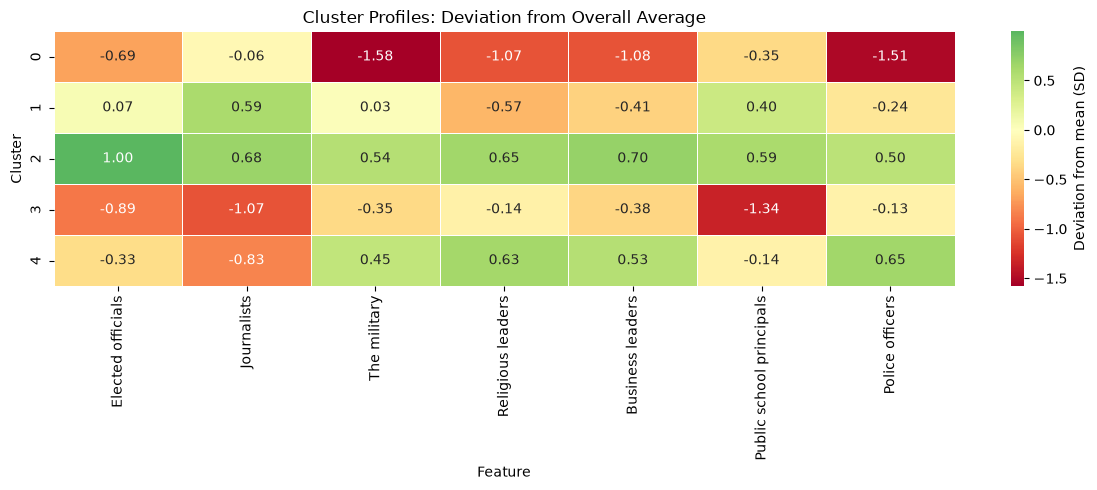

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

# Cluster means of scaled features = deviation from overall mean (in SD units)
cluster_profile = df.groupby("kmeans_5")[scaled_cols].mean()
cluster_profile.columns = dep_var_list  # cleaner labels
cluster_profile = cluster_profile.rename(columns=dep_labels)

plt.figure(figsize=(12, 5))
sns.heatmap(
    cluster_profile,
    cmap="RdYlGn",   
    center=0,        
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"label": "Deviation from mean (SD)"}
)
plt.title("Cluster Profiles: Deviation from Overall Average")
plt.xlabel("Feature")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

In [7]:
cluster_labels = {
    0: "Dislike enforcement",
    1: "Like journalists and principals",
    2: "Approving",
    3: "Dislike journalists and principals",
    4: "Like religious and police",
}

df["cluster_name"] = df["kmeans_5"].map(cluster_labels)

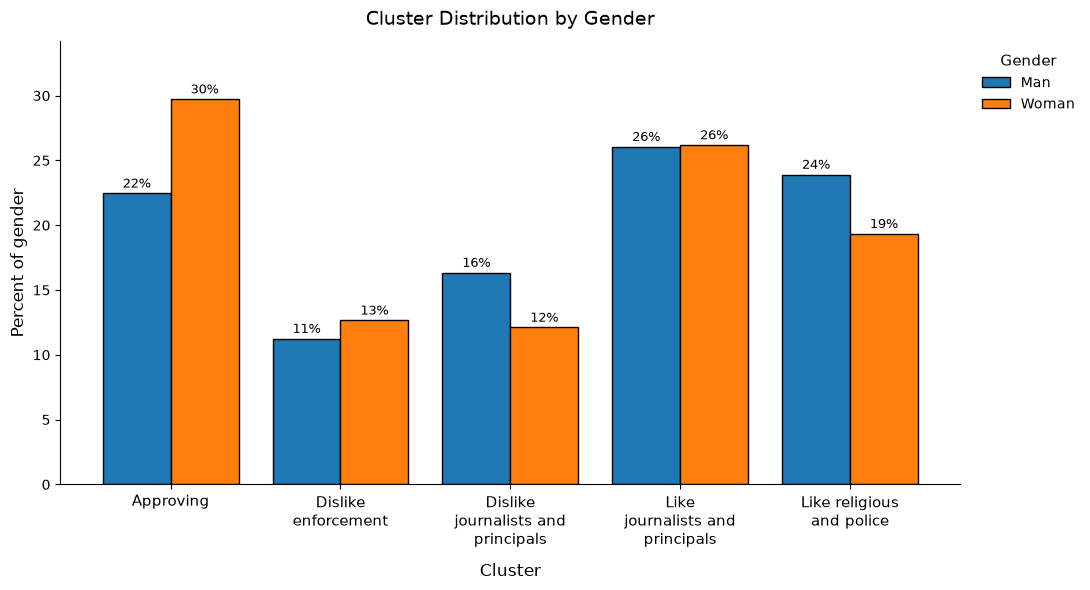

In [11]:
import textwrap
import pandas as pd
import matplotlib.pyplot as plt

# Party labels
gender_labels = {1: "Man", 2: "Woman"}
df["gender"] = df["F_GENDER"].map(gender_labels)

df["cluster_name"] = df["kmeans_5"].map(cluster_labels)

df = df.dropna(subset=["cluster_name", "gender"])

# Percent of each party group in each cluster
ct = pd.crosstab(df["cluster_name"], df["gender"], normalize="columns") * 100

# Wrap long labels to a maximum line width
WRAP_WIDTH = 15
ct.index = ["\n".join(textwrap.wrap(str(lbl), WRAP_WIDTH)) for lbl in ct.index]

# Scale figure width to the number of clusters
fig_width = max(8, 2.2 * len(ct.index))
ax = ct.plot(kind="bar", figsize=(fig_width, 6), width=0.8, edgecolor="black")

ax.set_xlabel("Cluster", fontsize=12, labelpad=10)
ax.set_ylabel("Percent of gender", fontsize=12)
ax.set_title("Cluster Distribution by Gender", fontsize=14, pad=12)
ax.tick_params(axis="x", labelsize=11, rotation=0)
ax.tick_params(axis="y", labelsize=10)

# Legend outside the plot area so it never covers bars
ax.legend(title="Gender", fontsize=10, title_fontsize=11,
          bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)

# Value labels with headroom above tallest bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f%%", fontsize=9, padding=2)
ax.set_ylim(0, ct.values.max() * 1.15)

ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

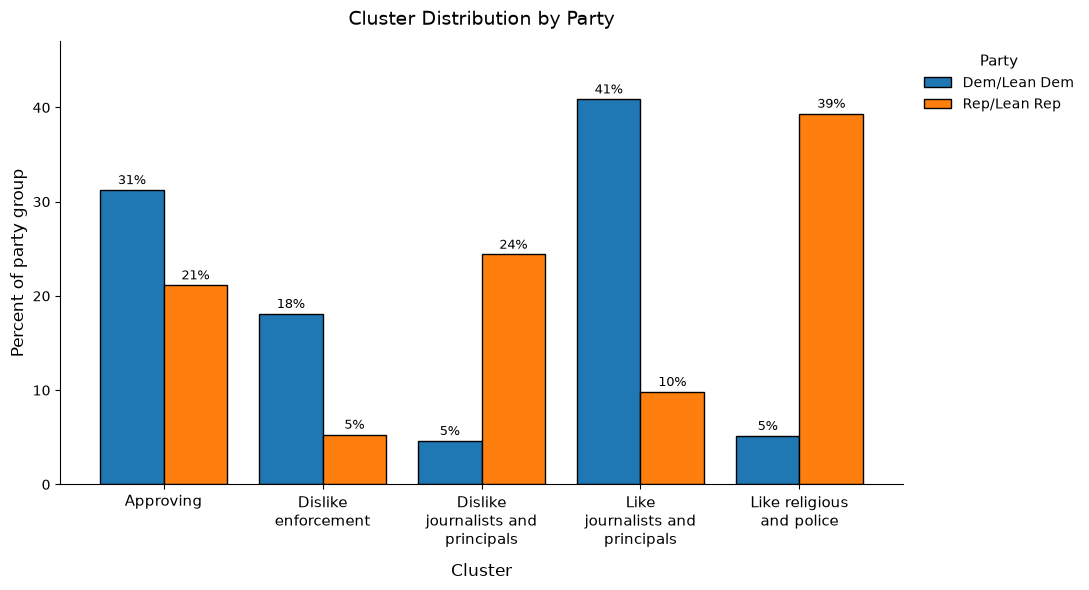

In [12]:
import textwrap
import pandas as pd
import matplotlib.pyplot as plt

# Party labels
party_labels = {1: "Rep/Lean Rep", 2: "Dem/Lean Dem", 9: "Refused/No lean"}
df["party"] = df["F_PARTYSUM_FINAL"].map(party_labels).fillna(df["F_PARTYSUM_FINAL"])

df["cluster_name"] = df["kmeans_5"].map(cluster_labels)

df = df.dropna(subset=["cluster_name", "party"])

# Percent of each party group in each cluster
ct = pd.crosstab(df["cluster_name"], df["party"], normalize="columns") * 100

# Wrap long labels to a maximum line width
WRAP_WIDTH = 15
ct.index = ["\n".join(textwrap.wrap(str(lbl), WRAP_WIDTH)) for lbl in ct.index]

# Scale figure width to the number of clusters
fig_width = max(8, 2.2 * len(ct.index))
ax = ct.plot(kind="bar", figsize=(fig_width, 6), width=0.8, edgecolor="black")

ax.set_xlabel("Cluster", fontsize=12, labelpad=10)
ax.set_ylabel("Percent of party group", fontsize=12)
ax.set_title("Cluster Distribution by Party", fontsize=14, pad=12)
ax.tick_params(axis="x", labelsize=11, rotation=0)
ax.tick_params(axis="y", labelsize=10)

# Legend outside the plot area so it never covers bars
ax.legend(title="Party", fontsize=10, title_fontsize=11,
          bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)

# Value labels with headroom above tallest bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f%%", fontsize=9, padding=2)
ax.set_ylim(0, ct.values.max() * 1.15)

ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

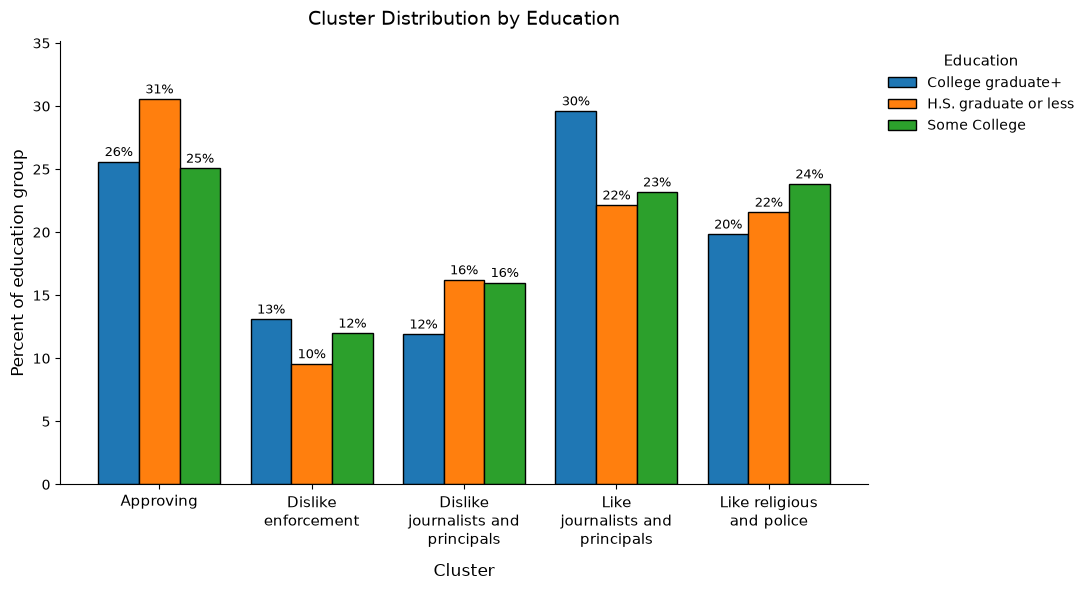

In [14]:
import textwrap
import pandas as pd
import matplotlib.pyplot as plt

ed_labels = {1: "College graduate+", 2: "Some College", 3: "H.S. graduate or less"}
df["education"] = df["F_EDUCCAT"].map(ed_labels)

df["cluster_name"] = df["kmeans_5"].map(cluster_labels)

df = df.dropna(subset=["cluster_name", "education"])

# Percent of each party group in each cluster
ct = pd.crosstab(df["cluster_name"], df["education"], normalize="columns") * 100

# Wrap long labels to a maximum line width
WRAP_WIDTH = 15
ct.index = ["\n".join(textwrap.wrap(str(lbl), WRAP_WIDTH)) for lbl in ct.index]

# Scale figure width to the number of clusters
fig_width = max(8, 2.2 * len(ct.index))
ax = ct.plot(kind="bar", figsize=(fig_width, 6), width=0.8, edgecolor="black")

ax.set_xlabel("Cluster", fontsize=12, labelpad=10)
ax.set_ylabel("Percent of education group", fontsize=12)
ax.set_title("Cluster Distribution by Education", fontsize=14, pad=12)
ax.tick_params(axis="x", labelsize=11, rotation=0)
ax.tick_params(axis="y", labelsize=10)

# Legend outside the plot area so it never covers bars
ax.legend(title="Education", fontsize=10, title_fontsize=11,
          bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)

# Value labels with headroom above tallest bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f%%", fontsize=9, padding=2)
ax.set_ylim(0, ct.values.max() * 1.15)

ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()